<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_deAbreu2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuantumNetSec: a variational quantum classifier for DDoS detection

This notebook re-implements the method of

> D. de Abreu, D. Moura, C. E. Rothenberg and A. Abelém, "QuantumNetSec: Quantum Machine Learning for Network Security," *International Journal of Network Management*, vol. 35, no. 4, e70018, 2025. https://doi.org/10.1002/nem.70018

The journal paper extends the authors' conference paper, "QML-IDS: Quantum Machine Learning Intrusion Detection System" ([arXiv:2410.16308](https://arxiv.org/abs/2410.16308)). Neither paper publishes code, so there is no official repository to build on. Everything below is written from the method as the papers describe it, using the same software stack (Qiskit, scikit-learn, TensorFlow) and the same set of quantum building blocks.

The notebook downloads CIC-IDS-2017 itself, trains a variational quantum classifier (VQC) to separate DDoS flows from benign traffic, and then repeats the paper's comparisons: QSVM and QCNN, three classical baselines, a 4 × 4 × 4 hyperparameter study, the five IBM devices under simulated noise, and per-attack multiclass F1.

**Runtime.** With `FAST_MODE = False` a full run takes roughly an hour on a two-core CPU (the standard free Colab runtime), most of it in the hyper-parameter study, the QCNN and the one-vs-rest multiclass QCNN. `FAST_MODE = True` cuts sample sizes and iteration budgets so the whole notebook, including the 700 MB multiclass download, finishes in about 10-15 minutes, which suits a live class demo; its scores are lower and noisier. On the machine used to validate this notebook (8-thread laptop CPU shared with other jobs, October 2026) the full run took 89 minutes and the fast run 9 minutes; the wall-clock time of the run that produced the saved outputs is printed in the last code cell. Running the full version before class and presenting the saved outputs works well. No GPU is needed.

## What follows the paper and what had to be chosen

The paper fixes the pipeline, the model families, the circuit libraries and the evaluation metric. It does not report qubit counts, feature reduction, sample sizes, train/test split, circuit repetitions, iteration budgets or shot counts. Where the paper is silent, this notebook makes a choice and says so in the code comments (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Pipeline | Monitoring → feature extraction → preprocessing → classical-to-quantum mapping → hybrid QML → output interpretation → alert | Same seven steps, one section each |
| Datasets | UNSW-NB15, CIC-IDS-2017, CICIoT2023 | CIC-IDS-2017 only (the DDoS use case) |
| Quantum models | VQC, QSVM, QCNN | VQC, QSVM (QSVC), QCNN |
| Feature maps | PauliFeatureMap, RawFeatureVector, ZFeatureMap, ZZFeatureMap | All four |
| Ansätze | EfficientSU2, ExcitationPreserving, RealAmplitudes, TwoLocal | All four |
| Optimizers | COBYLA, ADAM, SPSA, GradientDescent | All four |
| Transpilation / error handling | Optimization level 0–3, resilience 0/1, dynamical decoupling 0/1 | Levels 0–3 and dynamical decoupling on noise models of the paper's devices; resilience emulated with readout-error correction; real-hardware cell uses IBM Runtime options |
| Backends | QASM simulator, IBM Cairo, Kyoto, Brisbane, Osaka, Sherbrooke | Aer simulator plus Qiskit's fake versions of the same five devices (stored calibration snapshots, not live machines) |
| Classical baselines | RF, SVM (scikit-learn), CNN (TensorFlow) | Same |
| Metric | F1 score, binary and per attack class | Same |
| Qubits | Not reported (Fig. 1 circuits show 4) | 4 |
| Feature reduction | Not reported | Standardise → PCA to 4 components → rescale to [0, π] |
| Sample sizes, split, reps, maxiter, shots | Not reported | Set in the configuration cell |
| Hyper-parameter selection | 4 x 4 x 4 options listed (Table I / Table 3), winner and per-combination scores not reported | Section 5b: coordinate-wise search (10 trainings) or the full 64-combination grid, scored on a validation split of the training data |
| QSVM kernel | Not specified beyond "quantum kernel" | Fidelity kernel of the best non-amplitude feature map, exact statevector overlaps |
| Paper numbers used for comparison | Journal Table 6 (personalised optimisation) and conference Table IV (IBM Kyoto) | Both shown side by side |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships TensorFlow, scikit-learn and pandas.
!pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc

import importlib.util, subprocess, sys
if importlib.util.find_spec("tensorflow") is None:      # CNN baseline; preinstalled on most Colab images
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "tensorflow-cpu"], check=True)

Invalid -W option ignored: invalid module name: 'nbformat.validator'

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: small budgets, whole notebook in about 10-15 minutes; False: full budgets (about an hour)

SEED      = 42
N_QUBITS  = 4              # CHOICE: the paper does not report qubit counts; its Fig. 1 circuits use 4

# Binary task (BENIGN vs DDoS)
N_TRAIN, N_TEST = (120, 200) if FAST_MODE else (400, 400)
VQC_MAXITER      = 40  if FAST_MODE else 150     # CHOICE
QCNN_MAXITER     = 40  if FAST_MODE else 150     # CHOICE

# Hyperparameter study (paper Table I)
RUN_FULL_GRID    = False   # True: all 64 feature-map x ansatz x optimizer combinations (about 1.5-2 h)
GRID_TRAIN, GRID_VAL, GRID_MAXITER = (60, 60, 25) if FAST_MODE else (150, 150, 50)   # GRID_TRAIN + GRID_VAL <= N_TRAIN: both come out of the training split
GRAD_TRAIN, GRAD_MAXITER = (20, 5) if FAST_MODE else (30, 8)    # ADAM / GradientDescent use parameter-shift gradients: about 1 s per flow and step on a laptop CPU
NOTEBOOK_T0 = __import__("time").time()                          # wall clock for the whole run

# Noisy-device study (paper Tables II-III)
NOISY_N_TEST = 60 if FAST_MODE else 200
SHOTS        = 1024        # CHOICE

# Multiclass task (paper Table VI, CIC-IDS-17 column)
RUN_MULTICLASS        = True
MC_PER_CLASS          = 40 if FAST_MODE else 80   # flows sampled per attack family (60 % train / 40 % test)
MC_VQC_MAXITER        = 40 if FAST_MODE else 150
RUN_QCNN_MULTICLASS   = not FAST_MODE             # one-vs-rest QCNN: 7 trainings, about 10 min
MC_QCNN_MAXITER       = 60

# Optional: run the trained VQC on real IBM hardware (needs a free IBM Quantum Platform API key)
IBM_TOKEN    = ""          # paste your key here, or leave empty to skip
IBM_INSTANCE = None        # optional CRN of your instance

DATA_DIR = "cicids2017"

In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (z_feature_map, zz_feature_map, pauli_feature_map,
                                    real_amplitudes, efficient_su2, excitation_preserving, n_local, XGate)
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager, PassManager, Target
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
from qiskit_aer.primitives import SamplerV2 as AerSampler

from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.algorithms import VQC, QSVC, NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA, SPSA, ADAM, GradientDescent

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1


## 1. Network monitoring and data collection

The paper's first step is capturing traffic. Here that step is replaced by the public CIC-IDS-2017 capture from the Canadian Institute for Cybersecurity (Sharafaldin, Habibi Lashkari and Ghorbani, ICISSP 2018). Each row is one bidirectional flow summarised by CICFlowMeter, labelled BENIGN or with an attack name.

The binary task uses the Friday-afternoon file, which contains the LOIC DDoS attack against the victim web server alongside normal traffic. The download comes from a public Hugging Face mirror of UNB's `MachineLearningCSV` files; UNB's own site now puts the files behind a registration form. If the mirror is unreachable, the code falls back to a GitHub copy of the same day, which keeps every flow and label but only 26 of the 78 flow features.

In [4]:
import requests

HF_BASE = "https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/"
FALLBACK = {  # reduced-column copy, used only if the mirror is unreachable
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv":
        "https://raw.githubusercontent.com/StarterArcher/CICIDS2017/master/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
}

def download(fname, data_dir=DATA_DIR):
    # Download one CIC-IDS-2017 day file, trying the mirror first and the fallback second.
    os.makedirs(data_dir, exist_ok=True)
    path = os.path.join(data_dir, fname)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"already present: {fname}")
        return path
    for url in [HF_BASE + fname, FALLBACK.get(fname)]:
        if url is None:
            continue
        try:
            print(f"downloading {fname} from {url.split('/')[2]} ...", end=" ", flush=True)
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(path + ".part", "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            os.replace(path + ".part", path)
            print(f"{os.path.getsize(path)/1e6:.1f} MB")
            return path
        except Exception as e:
            print(f"failed ({e.__class__.__name__})")
    raise RuntimeError(f"could not download {fname}")

DDOS_FILE = download("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

already present: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


## 2. Feature extraction and 3. data preprocessing

CICFlowMeter has already extracted the flow statistics. Preprocessing follows what the paper lists (normalisation and handling of missing values) and adds the steps a quantum model needs:

1. Drop identifiers (IP addresses, ports, timestamps). They describe the lab network, not the attack, and a model that learns them would not transfer.
2. Replace infinite rates (division by a zero-length flow) with missing values and drop those rows; drop exact duplicates.
3. Draw a class-balanced sample. A statevector simulation costs time per sample, so the quantum models see hundreds of flows, not hundreds of thousands.
4. Fit the scaler and PCA on the training split only, then apply them to the test split, so no information from test flows leaks into training.
5. Reduce to `N_QUBITS` principal components (one feature per qubit) and rescale each to [0, π], the range of a rotation angle.

In [5]:
ID_COLUMNS = ["Flow ID", "Source IP", "Src IP", "Source Port", "Src Port", "Destination IP", "Dst IP",
              "Destination Port", "Dst Port", "Timestamp"]   # CHOICE: ports dropped as lab-specific identifiers

def load_flows(path):
    # Read one day file and return a cleaned DataFrame with numeric features and a Label column.
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    df = df.drop(columns=[c for c in ID_COLUMNS if c in df.columns])
    df["Label"] = df["Label"].astype(str).str.strip()
    feats = df.columns.drop("Label")
    df[feats] = df[feats].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
    return df

flows = load_flows(DDOS_FILE)
FEATURES = [c for c in flows.columns if c != "Label"]
print(f"{len(flows):,} clean flows, {len(FEATURES)} features")
print(flows["Label"].value_counts().to_string())

221,264 clean flows, 77 features
Label
DDoS      128014
BENIGN     93250


train (400, 4) test (400, 4)
variance kept by 4 components: 63.2%


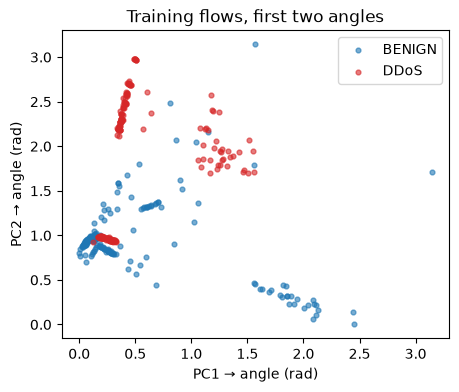

In [6]:
# Class-balanced sample, then a stratified train/test split
per_class = (N_TRAIN + N_TEST) // 2
sample = flows.groupby("Label").sample(n=per_class, random_state=SEED)
X_all = sample[FEATURES].to_numpy(float)
y_all = (sample["Label"] != "BENIGN").astype(int).to_numpy()      # 1 = DDoS (attack), 0 = benign

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, train_size=N_TRAIN, test_size=N_TEST, stratify=y_all, random_state=SEED)

# Fitted on training data only
to_qubits = make_pipeline(StandardScaler(), PCA(n_components=N_QUBITS, random_state=SEED),
                          MinMaxScaler(feature_range=(0, np.pi)))
X_train = to_qubits.fit_transform(X_train_raw)
X_test  = np.clip(to_qubits.transform(X_test_raw), 0, np.pi)

pca = to_qubits.named_steps["pca"]
print("train", X_train.shape, "test", X_test.shape)
print("variance kept by", N_QUBITS, "components:", f"{pca.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
for lab, name, c in [(0, "BENIGN", "tab:blue"), (1, "DDoS", "tab:red")]:
    m = y_train == lab
    ax.scatter(X_train[m, 0], X_train[m, 1], s=12, alpha=.6, label=name, c=c)
ax.set_xlabel("PC1 → angle (rad)"); ax.set_ylabel("PC2 → angle (rad)"); ax.legend(); ax.set_title("Training flows, first two angles")
plt.show()

## 4. Classical-to-quantum mapping: the four feature maps

A feature map $U_\phi(x)$ writes a classical vector $x$ into a quantum state $|\phi(x)\rangle = U_\phi(x)|0\rangle^{\otimes q}$. The paper tests the four maps in Qiskit's circuit library:

- **ZFeatureMap**: Hadamards followed by single-qubit phase rotations $P(2x_i)$. No entanglement, so each feature stays on its own qubit.
- **ZZFeatureMap**: adds two-qubit $ZZ$ phase terms $(\pi - x_i)(\pi - x_j)$, which entangle features. This is the map used in Havlíček et al. (Nature, 2019).
- **PauliFeatureMap**: the general form, where you choose the Pauli strings. The paper does not say which strings it used; this notebook uses `["Y", "ZZ"]` so that it differs from ZZFeatureMap (whose strings are `["Z", "ZZ"]`).
- **RawFeatureVector**: amplitude encoding. The normalised feature vector becomes the state's amplitudes, so 4 features need only $\log_2 4 = 2$ qubits.

ZFeatureMap: 4 qubits, 4 input parameters


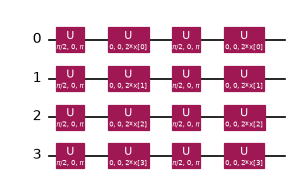

ZZFeatureMap: 4 qubits, 4 input parameters


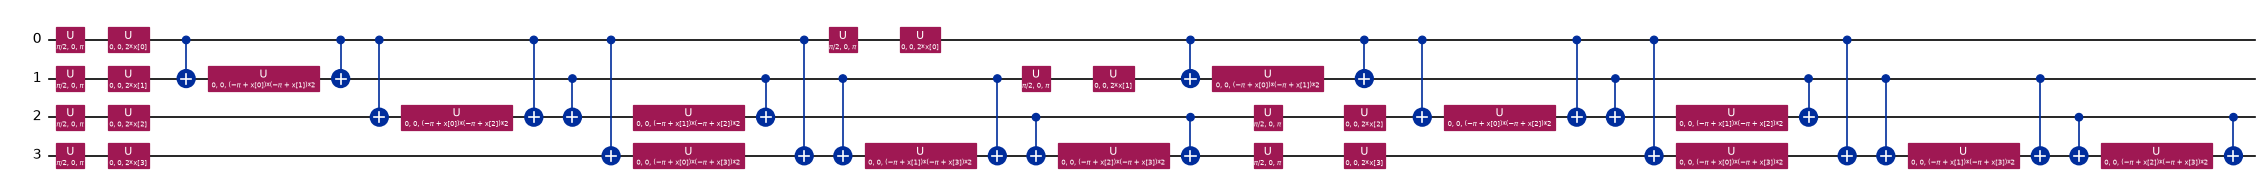

PauliFeatureMap: 4 qubits, 4 input parameters


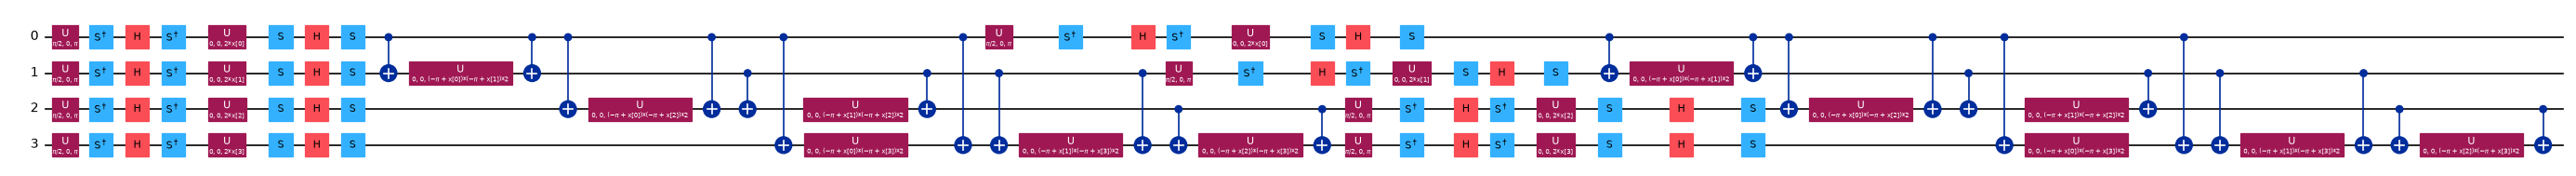

RawFeatureVector: 2 qubits, 4 input parameters


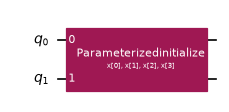

In [7]:
FEATURE_MAPS = ["ZFeatureMap", "ZZFeatureMap", "PauliFeatureMap", "RawFeatureVector"]
ANSATZE      = ["RealAmplitudes", "EfficientSU2", "ExcitationPreserving", "TwoLocal"]
OPTIMIZERS   = ["COBYLA", "SPSA", "ADAM", "GradientDescent"]

def build_feature_map(name, n=N_QUBITS):
    if name == "ZFeatureMap":      return z_feature_map(n, reps=2)                         # CHOICE: reps=2
    if name == "ZZFeatureMap":     return zz_feature_map(n, reps=2)
    if name == "PauliFeatureMap":  return pauli_feature_map(n, reps=2, paulis=["Y", "ZZ"])  # CHOICE: Pauli strings
    if name == "RawFeatureVector": return raw_feature_vector(n)                            # n features -> log2(n) qubits
    raise ValueError(name)

def build_ansatz(name, n):
    if name == "RealAmplitudes":       return real_amplitudes(n, reps=3)                    # CHOICE: reps
    if name == "EfficientSU2":         return efficient_su2(n, reps=2)
    if name == "ExcitationPreserving":   # its "Interaction" gate is rewritten into gates the Aer simulator knows
        return transpile(excitation_preserving(n, reps=2), basis_gates=["rz", "rx", "ry", "cx", "h", "p"], optimization_level=0)
    if name == "TwoLocal":             return n_local(n, ["ry", "rz"], "cz", reps=3)
    raise ValueError(name)

def build_optimizer(name, maxiter):
    if name == "COBYLA":          return COBYLA(maxiter=maxiter)
    if name == "SPSA":            return SPSA(maxiter=maxiter)
    if name == "ADAM":            return ADAM(maxiter=maxiter, lr=0.05)                     # CHOICE: learning rates
    if name == "GradientDescent": return GradientDescent(maxiter=maxiter, learning_rate=0.1)
    raise ValueError(name)

for name in FEATURE_MAPS:
    fm = build_feature_map(name)
    print(f"{name}: {fm.num_qubits} qubits, {fm.num_parameters} input parameters")
    display(fm.decompose().draw("mpl", fold=-1, scale=0.6) if name != "RawFeatureVector" else fm.draw("mpl", scale=0.6))

## 5. Hybrid QML processing: the variational quantum classifier

The VQC appends a trainable circuit $U(\theta)$, the ansatz, to the feature map and measures every qubit:

$$|\psi(x,\theta)\rangle = U(\theta)\,U_\phi(x)\,|0\rangle^{\otimes q}.$$

Qiskit's `VQC` reads the class from the measured bitstring's parity (an odd number of 1s means class 1), so $p(y=1\mid x)$ is the probability of an odd-parity outcome. A classical optimiser then adjusts $\theta$ to minimise the cross-entropy between these probabilities and the true labels. The quantum computer prepares and measures states; all learning happens on the classical side.

The first model uses a common default configuration (ZZFeatureMap + RealAmplitudes + COBYLA). Section 5b searches the paper's hyper-parameter space (coordinate-wise by default, the full 64-combination grid with `RUN_FULL_GRID = True`).

RealAmplitudes ansatz: 16 trainable angles


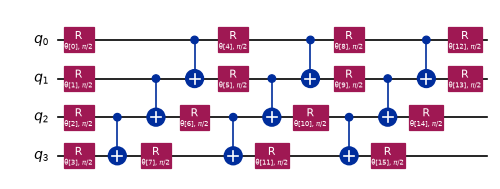

In [8]:
def make_live_plot(title, every=5):
    # Return (callback, history). The callback redraws the loss curve every few evaluations.
    history = []
    def callback(*args):
        # With COBYLA / ADAM / GradientDescent, VQC calls callback(weights, loss) after every loss evaluation. With SPSA,
        # qiskit-machine-learning 0.9 installs the function as SPSA's own callback instead, called once per step
        # with (n_evals, weights, loss, step_size, accepted); both signatures are accepted here.
        history.append(args[1] if len(args) == 2 else args[2])
        if len(history) % every == 0:
            clear_output(wait=True)
            plt.figure(figsize=(6, 3)); plt.plot(history); plt.xlabel("optimizer evaluation")
            plt.ylabel("cross-entropy loss"); plt.title(title); plt.show()
    return callback, history

def make_vqc(fm_name, an_name, opt_name, maxiter, callback=None):
    fm = build_feature_map(fm_name)
    an = build_ansatz(an_name, fm.num_qubits)
    # Aer cannot simulate RawFeatureVector's ParameterizedInitialize instruction, so that map uses Qiskit's reference sampler
    sampler = (StatevectorSampler(default_shots=SHOTS, seed=SEED) if fm_name == "RawFeatureVector"
               else AerSampler(default_shots=SHOTS, seed=SEED))
    return VQC(feature_map=fm, ansatz=an, optimizer=build_optimizer(opt_name, maxiter), callback=callback, sampler=sampler)

ansatz_demo = build_ansatz("RealAmplitudes", N_QUBITS)
print("RealAmplitudes ansatz:", ansatz_demo.num_parameters, "trainable angles")
display(ansatz_demo.decompose().draw("mpl", fold=-1, scale=0.6))

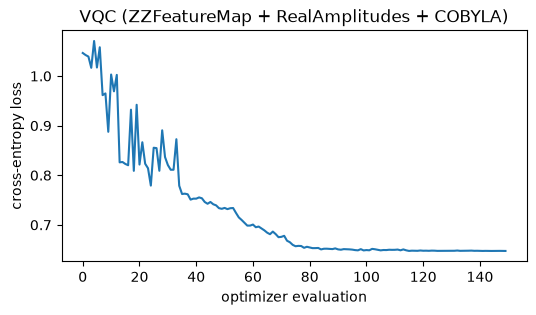

trained in 362 s | test F1 (DDoS = positive) = 0.7879


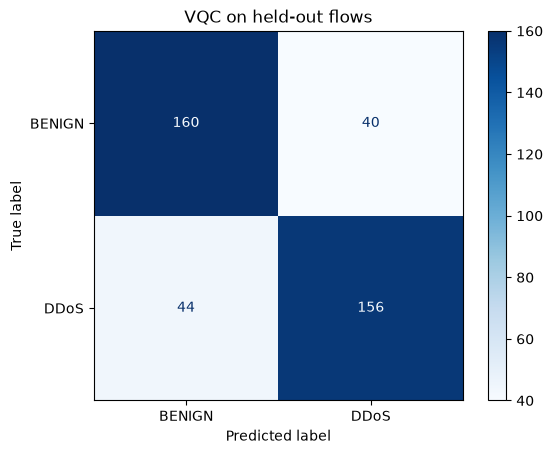

In [9]:
cb, hist = make_live_plot("VQC (ZZFeatureMap + RealAmplitudes + COBYLA)")
vqc = make_vqc("ZZFeatureMap", "RealAmplitudes", "COBYLA", VQC_MAXITER, callback=cb)
t0 = time.time(); vqc.fit(X_train, y_train); t_vqc = time.time() - t0

y_pred_vqc = vqc.predict(X_test)
print(f"trained in {t_vqc:.0f} s | test F1 (DDoS = positive) = {f1_score(y_test, y_pred_vqc):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_vqc), display_labels=["BENIGN", "DDoS"]).plot(cmap="Blues")
plt.title("VQC on held-out flows"); plt.show()

### 6–7. Output interpretation and alert generation

The paper's last two steps turn the measured class into an alert. The cell below shows this for a few test flows: the measured odd-parity probability is the model's DDoS score, and a score above 0.5 raises an alert.

In [10]:
proba = vqc.predict_proba(X_test[:8])
for i, p in enumerate(proba):
    verdict = "ALERT: DDoS" if p[1] >= 0.5 else "ok"
    truth = "DDoS" if y_test[i] else "BENIGN"
    print(f"flow {i}: p(DDoS) = {p[1]:.2f} -> {verdict:12s} (true label: {truth})")

flow 0: p(DDoS) = 0.17 -> ok           (true label: BENIGN)
flow 1: p(DDoS) = 0.71 -> ALERT: DDoS  (true label: DDoS)
flow 2: p(DDoS) = 0.80 -> ALERT: DDoS  (true label: DDoS)
flow 3: p(DDoS) = 0.79 -> ALERT: DDoS  (true label: DDoS)
flow 4: p(DDoS) = 0.39 -> ok           (true label: DDoS)
flow 5: p(DDoS) = 0.61 -> ALERT: DDoS  (true label: BENIGN)
flow 6: p(DDoS) = 0.74 -> ALERT: DDoS  (true label: DDoS)
flow 7: p(DDoS) = 0.34 -> ok           (true label: BENIGN)


## 5b. Hyper-parameter study (paper Table I)

The paper lists the options it searched - four feature maps, four ansätze and four classical optimizers (Table I of QML-IDS, Table 3 of the journal version) - but reports neither the per-combination scores nor the combination behind its headline numbers. This section runs that search so that the "VQC (tuned)" row of the comparison table is a reproducible choice rather than a guess.

Two rules keep the search honest:

- **Selection uses a validation split of the training data only.** `GRID_TRAIN` flows are used to fit, `GRID_VAL` other training flows to score. The test flows are untouched until the winning configuration has been retrained on the full training set.
- **The budget is stated.** With `RUN_FULL_GRID = False` (default) the search is coordinate-wise: all four feature maps with RealAmplitudes + COBYLA, then all four ansätze with the best map, then all four optimizers with the best map and ansatz, 10 trainings instead of 64. `RUN_FULL_GRID = True` evaluates every one of the 64 combinations (about 1.5-2 h on a Colab CPU). ADAM and GradientDescent need parameter-shift gradients (two extra circuits per trainable angle per flow per step), so they get the smaller `GRAD_TRAIN` / `GRAD_MAXITER` budget; the table records the budget next to each score, and a gradient optimizer can only win if it beats the others despite that handicap.

Every combination starts from the same random initial angles (`algorithm_globals.random_seed` is reset before each training), so the comparison is between configurations, not between lucky starts.

One corner of the paper's grid cannot be run as described: ADAM and GradientDescent need a gradient, Qiskit computes it with the parameter-shift rule, and that rule does not exist for RawFeatureVector's amplitude-encoding instruction. Those combinations are listed with an empty score. (With RawFeatureVector, Qiskit's `VQC` encodes 4 features on 2 qubits, so its ansatz is the 2-qubit version.)

grid: fit on 150 training flows, score on 150 validation flows


ZFeatureMap      RealAmplitudes       COBYLA          val F1 =  57.14 %  (  45.3 s)


ZZFeatureMap     RealAmplitudes       COBYLA          val F1 =  83.64 %  (  37.9 s)


PauliFeatureMap  RealAmplitudes       COBYLA          val F1 =  77.24 %  (  47.0 s)


RawFeatureVector RealAmplitudes       COBYLA          val F1 =  68.80 %  (  41.9 s)


...

ZZFeatureMap     TwoLocal             SPSA            val F1 =  86.96 %  ( 110.9 s)


ZZFeatureMap     TwoLocal             ADAM            val F1 =  69.28 %  ( 356.7 s)


ZZFeatureMap     TwoLocal             GradientDescent val F1 =  50.29 %  ( 357.9 s)



10 combinations (10 trained) in 18.8 min
BEST = Combo(feature_map='ZZFeatureMap', ansatz='TwoLocal', optimizer='SPSA')


,feature_map,ansatz,optimizer,train flows,maxiter,val F1 (%),time (s),note
0,ZZFeatureMap,TwoLocal,SPSA,150,50,86.96,110.9,
1,ZZFeatureMap,TwoLocal,COBYLA,150,50,85.03,42.1,
2,ZZFeatureMap,RealAmplitudes,COBYLA,150,50,83.64,37.9,
3,ZZFeatureMap,ExcitationPreserving,COBYLA,150,50,78.53,42.4,
4,PauliFeatureMap,RealAmplitudes,COBYLA,150,50,77.24,47.0,
5,ZZFeatureMap,EfficientSU2,COBYLA,150,50,71.53,36.0,
6,ZZFeatureMap,TwoLocal,ADAM,30,8,69.28,356.7,reduced gradient budget
7,RawFeatureVector,RealAmplitudes,COBYLA,150,50,68.80,41.9,
8,ZFeatureMap,RealAmplitudes,COBYLA,150,50,57.14,45.3,
9,ZZFeatureMap,TwoLocal,GradientDescent,30,8,50.29,357.9,reduced gradient budget


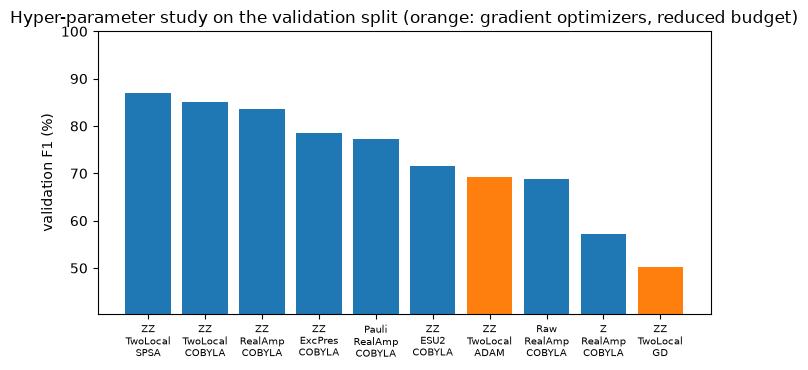

In [11]:
from collections import namedtuple
from itertools import product

Combo = namedtuple("Combo", ["feature_map", "ansatz", "optimizer"])
GRAD_OPTS = ("ADAM", "GradientDescent")

# Validation split carved out of the training data only; the test set is never touched here
n_val = min(GRID_VAL, N_TRAIN - GRID_TRAIN)
Xg_tr, Xg_val, yg_tr, yg_val = train_test_split(X_train, y_train, train_size=GRID_TRAIN, test_size=n_val,
                                                stratify=y_train, random_state=SEED)
print(f"grid: fit on {len(Xg_tr)} training flows, score on {len(Xg_val)} validation flows")

grid_results = {}

def evaluate(combo):
    # Train one configuration on the grid split and return its validation F1 (cached per combination)
    if combo in grid_results:
        return np.nan_to_num(grid_results[combo]["val F1 (%)"], nan=-1.0)
    gradient = combo.optimizer in GRAD_OPTS
    if gradient and combo.feature_map == "RawFeatureVector":
        # Qiskit's parameter-shift gradient has no rule for amplitude encoding (ParameterizedInitialize), and
        # VQC 0.9 offers no gradient-free fallback, so these combinations cannot be trained and are recorded as NaN
        grid_results[combo] = {**combo._asdict(), "train flows": 0, "maxiter": 0, "val F1 (%)": np.nan, "time (s)": 0.0,
                               "note": "no parameter-shift rule for amplitude encoding"}
        print(f"{combo.feature_map:16s} {combo.ansatz:20s} {combo.optimizer:15s} skipped: gradients undefined for RawFeatureVector", flush=True)
        return -1.0
    n_fit, maxiter = (GRAD_TRAIN, GRAD_MAXITER) if gradient else (len(Xg_tr), GRID_MAXITER)
    algorithm_globals.random_seed = SEED                      # same initial angles for every combination
    model = make_vqc(*combo, maxiter)
    t0 = time.time(); model.fit(Xg_tr[:n_fit], yg_tr[:n_fit]); t = time.time() - t0
    score = 100 * f1_score(yg_val, model.predict(Xg_val))
    grid_results[combo] = {**combo._asdict(), "train flows": n_fit, "maxiter": maxiter,
                           "val F1 (%)": round(score, 2), "time (s)": round(t, 1), "note": "reduced gradient budget" if gradient else ""}
    print(f"{combo.feature_map:16s} {combo.ansatz:20s} {combo.optimizer:15s} val F1 = {score:6.2f} %  ({t:6.1f} s)", flush=True)
    return score

t_grid = time.time()
if RUN_FULL_GRID:
    for fm, an, opt in product(FEATURE_MAPS, ANSATZE, OPTIMIZERS):
        evaluate(Combo(fm, an, opt))
    BEST = max(grid_results, key=lambda c: np.nan_to_num(grid_results[c]["val F1 (%)"], nan=-1.0))
else:
    # CHOICE: coordinate-wise search (10 trainings) instead of the full 64-combination grid; ties keep the first option
    best_fm  = max(FEATURE_MAPS, key=lambda fm: evaluate(Combo(fm, "RealAmplitudes", "COBYLA")))
    best_an  = max(ANSATZE,      key=lambda an: evaluate(Combo(best_fm, an, "COBYLA")))
    best_opt = max(OPTIMIZERS,   key=lambda op: evaluate(Combo(best_fm, best_an, op)))
    BEST = Combo(best_fm, best_an, best_opt)
t_grid = time.time() - t_grid

grid_df = pd.DataFrame(grid_results.values()).sort_values("val F1 (%)", ascending=False, na_position="last").reset_index(drop=True)
print(f"\n{len(grid_df)} combinations ({grid_df['val F1 (%)'].notna().sum()} trained) in {t_grid/60:.1f} min")
print(f"BEST = {BEST}")
display(grid_df)

short = {"ZFeatureMap": "Z", "ZZFeatureMap": "ZZ", "PauliFeatureMap": "Pauli", "RawFeatureVector": "Raw",
         "RealAmplitudes": "RealAmp", "EfficientSU2": "ESU2", "ExcitationPreserving": "ExcPres", "TwoLocal": "TwoLocal",
         "COBYLA": "COBYLA", "SPSA": "SPSA", "ADAM": "ADAM", "GradientDescent": "GD"}
plot_df = grid_df.dropna(subset=["val F1 (%)"])
fig, ax = plt.subplots(figsize=(max(7, 0.55 * len(plot_df)), 3.8))
colors = ["tab:orange" if o in GRAD_OPTS else "tab:blue" for o in plot_df["optimizer"]]
ax.bar(range(len(plot_df)), plot_df["val F1 (%)"], color=colors)
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels([f"{short[r.feature_map]}\n{short[r.ansatz]}\n{short[r.optimizer]}" for r in plot_df.itertuples()], fontsize=7)
ax.set_ylabel("validation F1 (%)"); ax.set_ylim(max(0, plot_df["val F1 (%)"].min() - 10), 100)
ax.set_title("Hyper-parameter study on the validation split (orange: gradient optimizers, reduced budget)")
plt.tight_layout(); plt.show()

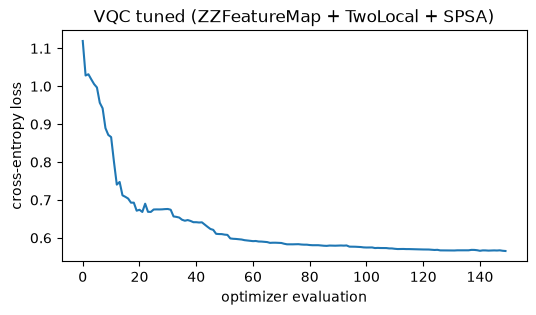

VQC (tuned): ZZFeatureMap + TwoLocal + SPSA, maxiter = 150, 400 training flows, trained in 1010 s
test F1 (DDoS = positive): tuned = 0.8544 | default ZZ + RealAmplitudes + COBYLA = 0.7879


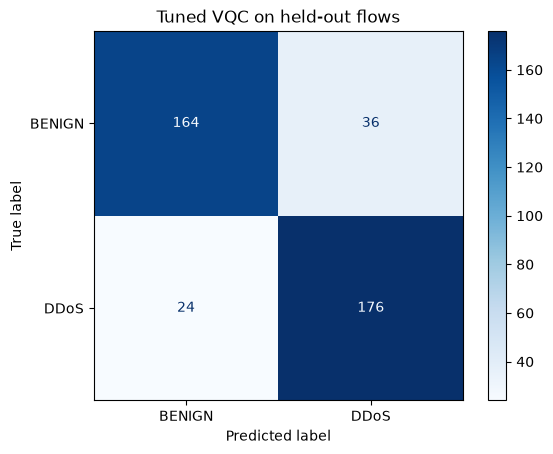

In [12]:
# Retrain the winning configuration on the full training set, then evaluate once on the test set
if BEST.optimizer in GRAD_OPTS:
    # CHOICE: parameter-shift gradients cost 2 x (trainable angles) circuits per flow per step (about 0.4 s per flow
    # and step on a CPU), so a gradient optimizer is retrained on a subset of the training flows with the GRAD budget
    n_final, final_maxiter = min(N_TRAIN, 4 * GRAD_TRAIN), GRAD_MAXITER
else:
    n_final, final_maxiter = N_TRAIN, VQC_MAXITER
algorithm_globals.random_seed = SEED
cb, hist_best = make_live_plot(f"VQC tuned ({BEST.feature_map} + {BEST.ansatz} + {BEST.optimizer})")
vqc_best = make_vqc(*BEST, final_maxiter, callback=cb)
t0 = time.time(); vqc_best.fit(X_train[:n_final], y_train[:n_final]); t_best = time.time() - t0   # X_train is already shuffled

y_pred_best = vqc_best.predict(X_test)
print(f"VQC (tuned): {BEST.feature_map} + {BEST.ansatz} + {BEST.optimizer}, maxiter = {final_maxiter}, {n_final} training flows, trained in {t_best:.0f} s")
print(f"test F1 (DDoS = positive): tuned = {f1_score(y_test, y_pred_best):.4f} | default ZZ + RealAmplitudes + COBYLA = {f1_score(y_test, y_pred_vqc):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best), display_labels=["BENIGN", "DDoS"]).plot(cmap="Blues")
plt.title("Tuned VQC on held-out flows"); plt.show()

## 5c. Quantum support vector machine (QSVC)

The QSVM replaces the trainable ansatz by a kernel. Two flows are compared through the overlap of their encoded states,

$$k(a, b) = \left|\langle \phi(a) | \phi(b) \rangle\right|^2,$$

and a classical SVM (scikit-learn's `SVC` with `kernel="precomputed"`, wrapped by Qiskit's `QSVC`) finds the separating hyperplane in that feature space. Nothing is optimised on the quantum side: training needs one kernel entry per pair of training flows and no iterations, which is why the QSVM is the fastest of the three quantum models here.

`FidelityStatevectorKernel` computes the overlaps exactly from statevectors. The feature map is the best map of Section 5b, excluding RawFeatureVector: with amplitude encoding of 4 normalised features the overlap is just the squared cosine similarity of the raw vectors, which a classical kernel already provides, so it is not an interesting quantum kernel. The cell also recomputes a corner of the kernel matrix by hand from `Statevector` objects to show there is nothing hidden in the library call.

kernel feature map: ZZFeatureMap | validation F1 per map: {'ZFeatureMap': 57.14, 'ZZFeatureMap': 83.64, 'PauliFeatureMap': 77.24}


QSVC: test F1 (DDoS = positive) = 0.9578 (4.9 s for training and prediction)


hand-computed |<phi(a)|phi(b)>|^2 matches FidelityStatevectorKernel: True


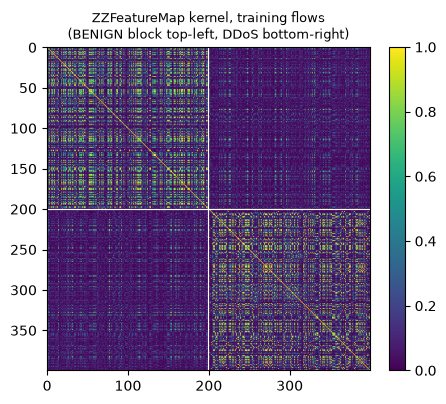

In [13]:
from qiskit.quantum_info import Statevector

# CHOICE: best feature map on the validation split (RealAmplitudes + COBYLA stage), RawFeatureVector excluded
fm_scores = {c.feature_map: r["val F1 (%)"] for c, r in grid_results.items()
             if c.ansatz == "RealAmplitudes" and c.optimizer == "COBYLA" and c.feature_map != "RawFeatureVector"}
kernel_fm_name = max(fm_scores, key=fm_scores.get) if fm_scores else "ZZFeatureMap"
print("kernel feature map:", kernel_fm_name, "| validation F1 per map:", fm_scores)

qkernel = FidelityStatevectorKernel(feature_map=build_feature_map(kernel_fm_name))
qsvc = QSVC(quantum_kernel=qkernel, random_state=SEED)
t0 = time.time(); qsvc.fit(X_train, y_train); y_pred_qsvc = qsvc.predict(X_test); t_qsvc = time.time() - t0
print(f"QSVC: test F1 (DDoS = positive) = {f1_score(y_test, y_pred_qsvc):.4f} ({t_qsvc:.1f} s for training and prediction)")

# Cross-check: the same kernel entries computed by hand from statevectors
K_train = qkernel.evaluate(X_train)
fm_k = build_feature_map(kernel_fm_name)
states = [Statevector(fm_k.assign_parameters(x)) for x in X_train[:20]]
K_hand = np.abs(np.array([[a.inner(b) for b in states] for a in states])) ** 2
print("hand-computed |<phi(a)|phi(b)>|^2 matches FidelityStatevectorKernel:", np.allclose(K_hand, K_train[:20, :20], atol=1e-6))

order = np.argsort(y_train, kind="stable")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(K_train[order][:, order], cmap="viridis", vmin=0, vmax=1)
ax.axhline((y_train == 0).sum() - .5, color="w", lw=.8); ax.axvline((y_train == 0).sum() - .5, color="w", lw=.8)
ax.set_title(f"{kernel_fm_name} kernel, training flows\n(BENIGN block top-left, DDoS bottom-right)", fontsize=9)
plt.colorbar(im, fraction=0.046); plt.show()

## 5d. Quantum convolutional neural network

The QCNN follows the construction in Qiskit's QCNN tutorial (after Cong, Choi and Lukin, *Nature Physics*, 2019). A convolution layer applies the same parametrised two-qubit block to neighbouring pairs; a pooling layer then folds half of the qubits into the other half. With 4 qubits the circuit runs conv → pool (4 → 2) → conv → pool (2 → 1), and the class is read from $\langle Z\rangle$ on the last remaining qubit: positive means BENIGN, negative means DDoS after mapping labels to ±1.

QCNN ansatz: 24 trainable angles


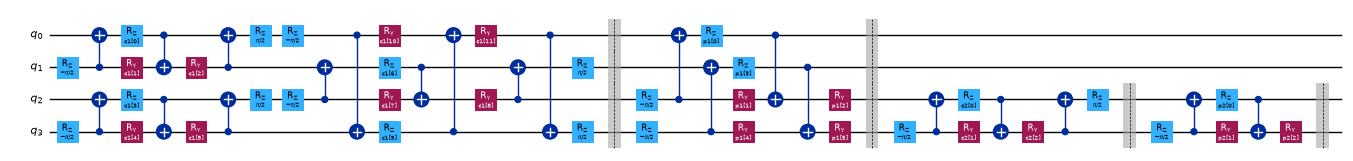

In [14]:
def conv_block(p):
    qc = QuantumCircuit(2)
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1)
    qc.cx(0, 1); qc.ry(p[2], 1); qc.cx(1, 0); qc.rz(np.pi / 2, 0)
    return qc

def pool_block(p):
    qc = QuantumCircuit(2)
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1); qc.cx(0, 1); qc.ry(p[2], 1)
    return qc

def conv_layer(n, prefix):
    q = list(range(n))
    pairs = [(0, 1)] if n == 2 else list(zip(q[0::2], q[1::2])) + list(zip(q[1::2], q[2::2] + [0]))
    params = ParameterVector(prefix, 3 * len(pairs)); qc = QuantumCircuit(n)
    for k, (a, b) in enumerate(pairs):
        qc.compose(conv_block(params[3 * k:3 * k + 3]), [a, b], inplace=True)
    qc.barrier(); return qc

def pool_layer(n, prefix):
    half = n // 2; params = ParameterVector(prefix, 3 * half); qc = QuantumCircuit(n)
    for k, (src, sink) in enumerate(zip(range(half), range(half, n))):
        qc.compose(pool_block(params[3 * k:3 * k + 3]), [src, sink], inplace=True)
    qc.barrier(); return qc

def qcnn_circuit(n=N_QUBITS):
    assert n & (n - 1) == 0, "QCNN pooling halves the register, so N_QUBITS must be a power of two"
    ansatz = QuantumCircuit(n); active = list(range(n)); layer = 1
    while len(active) > 1:
        ansatz.compose(conv_layer(len(active), f"c{layer}"), active, inplace=True)
        ansatz.compose(pool_layer(len(active), f"p{layer}"), active, inplace=True)
        active = active[len(active) // 2:]; layer += 1
    fm = build_feature_map("ZZFeatureMap", n)                 # CHOICE: QCNN feature map
    circuit = fm.compose(ansatz)
    observable = SparsePauliOp.from_sparse_list([("Z", [active[0]], 1.0)], num_qubits=n)
    return circuit, fm, ansatz, observable

def make_qcnn(maxiter, callback=None):
    circuit, fm, ansatz, obs = qcnn_circuit()
    qnn = EstimatorQNN(circuit=circuit, observables=obs, input_params=fm.parameters,
                       weight_params=ansatz.parameters, estimator=StatevectorEstimator())
    return NeuralNetworkClassifier(qnn, optimizer=COBYLA(maxiter=maxiter), callback=callback)

_, _, qcnn_ansatz, _ = qcnn_circuit()
print("QCNN ansatz:", qcnn_ansatz.num_parameters, "trainable angles")
display(qcnn_ansatz.draw("mpl", fold=-1, scale=0.5))

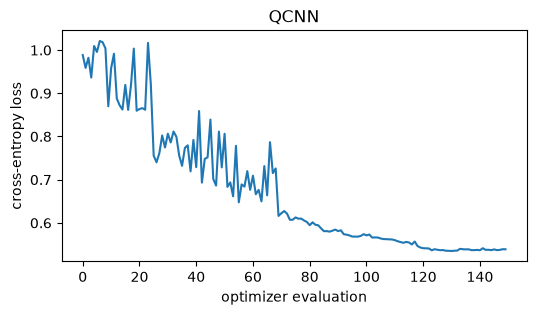

QCNN: test F1 = 0.8148 (324 s)


In [15]:
cb, hist = make_live_plot("QCNN")
qcnn = make_qcnn(QCNN_MAXITER, callback=cb)
t0 = time.time(); qcnn.fit(X_train, 2 * y_train - 1); t_qcnn = time.time() - t0     # labels as -1 / +1
y_pred_qcnn = (np.ravel(qcnn.predict(X_test)) > 0).astype(int)
print(f"QCNN: test F1 = {f1_score(y_test, y_pred_qcnn):.4f} ({t_qcnn:.0f} s)")

## 5e. Classical baselines

The paper compares against a random forest and an SVM from scikit-learn and a CNN in TensorFlow. Each baseline is trained twice:

- on the same 4 PCA angles the quantum models see, which isolates the effect of the model;
- on all flow features (standardised), which is what a practitioner would actually deploy.

The paper does not say which input its baselines used. Reporting both keeps the comparison honest.

In [16]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import tensorflow as tf
tf.random.set_seed(SEED); tf.get_logger().setLevel("ERROR")

def cnn_classifier(n_features, n_classes):
    # CHOICE: small 1-D CNN; the paper does not give its architecture
    out, loss = (1, "binary_crossentropy") if n_classes == 2 else (n_classes, "sparse_categorical_crossentropy")
    model = tf.keras.Sequential([
        tf.keras.layers.Input((n_features, 1)),
        tf.keras.layers.Conv1D(16, 2, padding="same", activation="relu"),
        tf.keras.layers.Conv1D(16, 2, padding="same", activation="relu"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(out, activation="sigmoid" if n_classes == 2 else "softmax")])
    model.compile(optimizer="adam", loss=loss)
    return model

def run_classical(Xtr, ytr, Xte, n_classes=2):
    preds = {}
    preds["RF"]  = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xtr, ytr).predict(Xte)
    preds["SVM"] = SVC(kernel="rbf", random_state=SEED).fit(Xtr, ytr).predict(Xte)
    cnn = cnn_classifier(Xtr.shape[1], n_classes)
    cnn.fit(Xtr[..., None], ytr, epochs=60, batch_size=32, verbose=0)
    p = cnn.predict(Xte[..., None], verbose=0)
    preds["CNN"] = (p.ravel() > 0.5).astype(int) if n_classes == 2 else p.argmax(1)
    return preds

classic_q = run_classical(X_train, y_train, X_test)                       # same 4 angles
full = StandardScaler().fit(X_train_raw)
classic_full = run_classical(full.transform(X_train_raw), y_train, full.transform(X_test_raw))
for k in classic_q:
    print(f"{k:4s} F1 on 4 PCA angles = {f1_score(y_test, classic_q[k]):.4f} | on all {len(FEATURES)} features = {f1_score(y_test, classic_full[k]):.4f}")

RF   F1 on 4 PCA angles = 0.9925 | on all 77 features = 0.9975
SVM  F1 on 4 PCA angles = 0.9724 | on all 77 features = 0.9901
CNN  F1 on 4 PCA angles = 0.9804 | on all 77 features = 0.9975


### Binary results next to the paper

Two sets of paper numbers are shown. The conference version (QML-IDS, arXiv:2410.16308, Table IV) reports the CIC-IDS-17 column with its models run on IBM Kyoto; the journal version (Table 6) reports higher values after "personalised" transpiler optimisation. The classical baselines are identical in both. Differences from this notebook are expected: the paper's sample sizes, feature reduction and iteration budgets are unknown, and this run uses a few hundred flows reduced to 4 angles.

Verdict rule used below: a paper value counts as *reproduced* when the notebook's score on the same 4 angles is within 3 F1 points of it or above it, *not reached here* otherwise. The paper's ordering claim (quantum above classical) is checked on identical inputs.

,"this notebook, 4 angles (%)","this notebook, all 77 features (%)","paper, conference Table IV (%)","paper, journal Table 6 (%)",train+predict time (s)
VQC (default),78.79,NaN,NaN,NaN,362.0
VQC (tuned),85.44,NaN,94.78,96.00,1009.9
QSVM,95.78,NaN,94.40,95.60,4.9
QCNN,81.48,NaN,95.60,97.15,323.7
RF,99.25,99.75,92.45,92.45,NaN
SVM,97.24,99.01,93.78,93.78,NaN
CNN,98.04,99.75,93.15,93.15,NaN


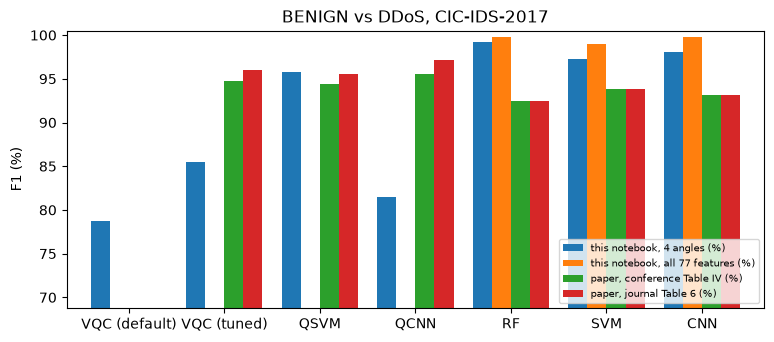

Verdicts (same 4 PCA angles for every model):
  VQC (tuned)  paper  94.78 | notebook  85.44 -> not reached here
  QSVM         paper  94.40 | notebook  95.78 -> reproduced
  QCNN         paper  95.60 | notebook  81.48 -> not reached here
  RF           paper  92.45 | notebook  99.25 -> reproduced
  SVM          paper  93.78 | notebook  97.24 -> reproduced
  CNN          paper  93.15 | notebook  98.04 -> reproduced
  'QML models outperform classical ML' (paper Sec. 6.3): best quantum 95.78 vs best classical 99.25 on the same inputs -> not reached here
  Per-device F1 on real IBM hardware (Tables II-III / Table 5): cannot be checked, the devices are retired; Section 6 uses their stored noise models


In [17]:
PAPER_BINARY_CICIDS17 = {"VQC (tuned)": 94.78, "QSVM": 94.40, "QCNN": 95.60, "RF": 92.45, "SVM": 93.78, "CNN": 93.15}   # QML-IDS Table IV (IBM Kyoto)
PAPER_JOURNAL_CICIDS17 = {"VQC (tuned)": 96.0, "QSVM": 95.6, "QCNN": 97.15, "RF": 92.45, "SVM": 93.78, "CNN": 93.15}   # QuantumNetSec Table 6 (personalised)

f1 = lambda p: 100 * f1_score(y_test, p)
ours4 = {"VQC (default)": f1(y_pred_vqc), "VQC (tuned)": f1(y_pred_best), "QSVM": f1(y_pred_qsvc), "QCNN": f1(y_pred_qcnn),
         **{k: f1(v) for k, v in classic_q.items()}}
binary = pd.DataFrame({
    "this notebook, 4 angles (%)": ours4,
    f"this notebook, all {len(FEATURES)} features (%)": {k: f1(v) for k, v in classic_full.items()},
    "paper, conference Table IV (%)": PAPER_BINARY_CICIDS17,
    "paper, journal Table 6 (%)": PAPER_JOURNAL_CICIDS17,
}).round(2)
binary["train+predict time (s)"] = pd.Series({"VQC (default)": t_vqc, "VQC (tuned)": t_best, "QSVM": t_qsvc, "QCNN": t_qcnn}).round(1)
display(binary)

ax = binary.iloc[:, :4].plot.bar(figsize=(9, 3.6), rot=0, width=.8); ax.set_ylabel("F1 (%)")
ax.set_ylim(max(0, np.nanmin(binary.iloc[:, :4].values) - 10), 100.5); ax.legend(loc="lower right", fontsize=7)
ax.set_title("BENIGN vs DDoS, CIC-IDS-2017"); plt.show()

# Claim-by-claim verdicts
print("Verdicts (same 4 PCA angles for every model):")
for model, paper in PAPER_BINARY_CICIDS17.items():
    ours = ours4[model]
    verdict = "reproduced" if ours >= paper - 3 else "not reached here"
    print(f"  {model:12s} paper {paper:6.2f} | notebook {ours:6.2f} -> {verdict}")
best_q = max(ours4[k] for k in ["VQC (tuned)", "QSVM", "QCNN"]); best_c = max(ours4[k] for k in classic_q)
print(f"  'QML models outperform classical ML' (paper Sec. 6.3): best quantum {best_q:.2f} vs best classical {best_c:.2f} on the same inputs -> "
      + ("reproduced" if best_q >= best_c else "not reached here"))
print("  Per-device F1 on real IBM hardware (Tables II-III / Table 5): cannot be checked, the devices are retired; Section 6 uses their stored noise models")

## 6. From simulator to NISQ devices (paper Tables II–III)

The paper re-ran its models on five IBM devices (Cairo, Kyoto, Brisbane, Osaka, Sherbrooke) with transpiler optimisation levels 0–3, two Runtime resilience levels and dynamical decoupling on or off. Most of those machines have since been retired, so this section uses Qiskit's *fake* versions of the same five devices: each one carries a stored snapshot of that device's qubit layout, native gates, gate errors, readout errors and coherence times, and Aer turns the snapshot into a noise model.

The trained VQC weights are kept fixed; only inference runs on the noisy devices. For each device the cell measures test F1 under:

- **optimisation levels 0–3**: how hard the transpiler works to shorten the circuit after mapping it onto the device's qubit graph and native gates;
- **dynamical decoupling (DD)**: X–X pulse pairs inserted into idle periods to refocus dephasing;
- **readout correction (RO)**: inverting each qubit's measured confusion matrix. On IBM Runtime the Estimator's `resilience_level=1` applies a related readout technique (TREX); the paper's resilience setting is approximated here, not reproduced.

model run under device noise: tuned VQC (ZZFeatureMap)


ibm_cairo done


ibm_kyoto done


ibm_brisbane done


ibm_osaka done


ibm_sherbrooke done


noiseless Aer simulator, same 200 flows: F1 = 88.58 %


,opt 0,opt 1,opt 2,opt 3,depth (opt 3),2q gates (opt 3),opt 3 + DD,opt 3 + DD + RO,"paper VQC, Tables II-III (%)"
device,,,,,,,,,
ibm_cairo,86.64,86.11,86.76,86.76,373,99,86.67,86.67,93.60
ibm_kyoto,52.83,59.53,56.25,56.25,369,72,56.25,54.55,94.78
ibm_brisbane,83.26,88.18,86.88,86.88,340,72,84.44,84.44,92.40
ibm_osaka,88.18,84.58,86.36,88.79,346,72,86.76,86.76,94.12
ibm_sherbrooke,87.78,86.64,86.11,89.19,340,72,87.27,87.67,94.00


noisy-device F1 range over all settings: 52.83 - 89.19 % (best per device: {'ibm_cairo': 86.76, 'ibm_kyoto': 59.53, 'ibm_brisbane': 88.18, 'ibm_osaka': 88.79, 'ibm_sherbrooke': 89.19})


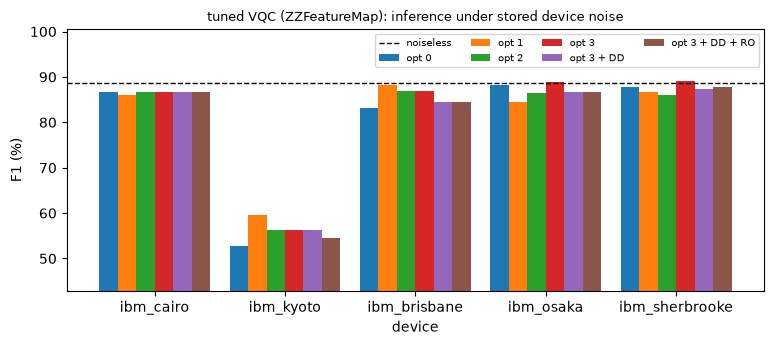

In [18]:
from qiskit_ibm_runtime.fake_provider import FakeCairoV2, FakeKyoto, FakeBrisbane, FakeOsaka, FakeSherbrooke

# Noise study uses the default ZZ VQC unless the tuned model's feature map can be transpiled with free parameters
# (RawFeatureVector's amplitude encoding is a state-preparation instruction, not a parametrised gate sequence)
noisy_model = vqc_best if BEST.feature_map != "RawFeatureVector" else vqc
noisy_name = f"tuned VQC ({BEST.feature_map})" if noisy_model is vqc_best else "default VQC (ZZFeatureMap + RealAmplitudes + COBYLA)"
print("model run under device noise:", noisy_name)
fm_n, an_n = noisy_model.feature_map, noisy_model.ansatz
logical = fm_n.compose(an_n); logical.measure_all()
Xn, yn = X_test[:NOISY_N_TEST], y_test[:NOISY_N_TEST]

def parity_p1(probs):
    # probability of odd parity (class 1) from a 2^n probability vector indexed by bitstring integer
    # Qiskit's VQC assigns outcome integer k to class k % 2 (the value of the qubit-0 bit)
    return probs[np.arange(len(probs)) % 2 == 1].sum()

def readout_matrix(backend, isa):
    # Tensor product of single-qubit confusion matrices for the physical qubits the circuit was mapped to
    phys = isa.layout.final_index_layout()[:fm_n.num_qubits]
    A = np.array([[1.0]])
    for q in phys:                                  # qubit 0 is the least significant bit, so it goes last
        e = backend.target["measure"][(q,)].error or 0.0
        A = np.kron(np.array([[1 - e, e], [e, 1 - e]]), A)
    return A

def device_target(backend):
    # FakeCairoV2's stored calibration lists CX on some couplers and ECR on others, a mix the transpiler
    # cannot orient. For such devices, transpile onto the ECR couplers only; noise still comes from the full snapshot.
    t = backend.target
    if not {"cx", "ecr"} <= set(t.operation_names):
        return t
    reduced = Target(num_qubits=t.num_qubits, dt=t.dt, description=f"{backend.name}, ECR couplers only")
    for name in ["ecr", "rz", "sx", "x", "id", "measure", "delay", "reset"]:
        if name in t.operation_names:
            reduced.add_instruction(t.operation_from_name(name), dict(t[name]), name=name)
    return reduced

def noisy_f1(backend, opt_level, dd=False, ro=False):
    target = device_target(backend)
    # Level 0 places virtual qubit i on physical qubit i. On devices whose stored calibration marks some
    # couplers as broken, qubits 0..3 are not connected, so level 0 then reuses the level-1 placement.
    try:
        pm = generate_preset_pass_manager(optimization_level=opt_level, target=target, seed_transpiler=SEED)
        pm.run(logical)
    except Exception:
        layout = generate_preset_pass_manager(optimization_level=1, target=target, seed_transpiler=SEED).run(logical).layout
        pm = generate_preset_pass_manager(optimization_level=opt_level, target=target, seed_transpiler=SEED,
                                          initial_layout=layout.initial_index_layout()[:logical.num_qubits])
    if dd:
        pm.scheduling = PassManager([ALAPScheduleAnalysis(target=target),
                                     PadDynamicalDecoupling(target=target, dd_sequence=[XGate(), XGate()])])
    isa = pm.run(logical)
    values = {**{p: Xn[:, i] for i, p in enumerate(fm_n.parameters)},
              **{p: np.full(len(Xn), w) for p, w in zip(an_n.parameters, noisy_model.weights)}}
    binds = np.column_stack([values[p] for p in isa.parameters])
    sampler = AerSampler.from_backend(backend, default_shots=SHOTS, seed=SEED)
    data = sampler.run([(isa, binds)]).result()[0].data.meas
    A_inv = np.linalg.pinv(readout_matrix(backend, isa)) if ro else None
    preds = []
    for i in range(len(Xn)):
        counts = data[i].get_counts()
        probs = np.zeros(2 ** fm_n.num_qubits)
        for bits, c in counts.items():
            probs[int(bits, 2)] += c
        probs /= probs.sum()
        if ro:
            probs = np.clip(A_inv @ probs, 0, None); probs /= probs.sum()
        preds.append(int(parity_p1(probs) >= 0.5))
    two_q = sum(v for k, v in isa.count_ops().items() if k in ("ecr", "cz", "cx"))
    return 100 * f1_score(yn, preds), isa.depth(), two_q

ideal = 100 * f1_score(yn, noisy_model.predict(Xn))
rows = []
for backend in [FakeCairoV2(), FakeKyoto(), FakeBrisbane(), FakeOsaka(), FakeSherbrooke()]:
    row = {"device": backend.name.replace("fake_", "ibm_")}
    for lvl in range(4):
        row[f"opt {lvl}"], depth, twoq = noisy_f1(backend, lvl)
        if lvl == 3: row["depth (opt 3)"], row["2q gates (opt 3)"] = depth, twoq
    row["opt 3 + DD"] = noisy_f1(backend, 3, dd=True)[0]
    row["opt 3 + DD + RO"] = noisy_f1(backend, 3, dd=True, ro=True)[0]
    rows.append(row); print(row["device"], "done", flush=True)

noisy_df = pd.DataFrame(rows).set_index("device").round(2)
# QML-IDS Tables II-III, CIC-IDS-17 row of the VQC (real devices, 2024 calibration); the journal's Table 5 lists 93.75 / 96.0 / 95.22 / 95.9 / 94.0
noisy_df["paper VQC, Tables II-III (%)"] = pd.Series({"ibm_cairo": 93.60, "ibm_kyoto": 94.78, "ibm_brisbane": 92.40, "ibm_osaka": 94.12, "ibm_sherbrooke": 94.00})
print(f"noiseless Aer simulator, same {len(Xn)} flows: F1 = {ideal:.2f} %")
display(noisy_df)
f1_cols = [c for c in noisy_df.columns if c.startswith("opt")]
print(f"noisy-device F1 range over all settings: {noisy_df[f1_cols].values.min():.2f} - {noisy_df[f1_cols].values.max():.2f} % "
      f"(best per device: {noisy_df[f1_cols].max(axis=1).round(2).to_dict()})")
ax = noisy_df[f1_cols].plot.bar(figsize=(9, 3.4), rot=0, width=.85); ax.axhline(ideal, color="k", ls="--", lw=1, label="noiseless")
ax.set_ylabel("F1 (%)"); ax.set_ylim(max(0, noisy_df[f1_cols].values.min() - 10), 100.5); ax.legend(fontsize=7, ncol=4)
ax.set_title(f"{noisy_name}: inference under stored device noise", fontsize=9); plt.show()

### Optional: the same circuit on a real IBM device

This cell only runs if you paste an IBM Quantum Platform API key into `IBM_TOKEN` in the configuration cell (the open plan includes a monthly free allowance). It sends the test flows as one batched job to the least busy device with dynamical decoupling and measurement twirling switched on. Queue times vary from seconds to hours.

In [19]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as RuntimeSampler
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN, instance=IBM_INSTANCE)
    hw = service.least_busy(operational=True, simulator=False)
    print("running on", hw.name)
    isa = generate_preset_pass_manager(optimization_level=3, backend=hw, seed_transpiler=SEED).run(logical)
    values = {**{p: Xn[:, i] for i, p in enumerate(fm_n.parameters)},
              **{p: np.full(len(Xn), w) for p, w in zip(an_n.parameters, noisy_model.weights)}}
    binds = np.column_stack([values[p] for p in isa.parameters])
    sampler = RuntimeSampler(mode=hw)
    sampler.options.default_shots = SHOTS
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XX"
    sampler.options.twirling.enable_measure = True
    job = sampler.run([(isa, binds)]); print("job id:", job.job_id())
    data = job.result()[0].data.meas
    preds = []
    for i in range(len(Xn)):
        counts = data[i].get_counts(); total = sum(counts.values())
        preds.append(int(sum(c for b, c in counts.items() if int(b, 2) % 2 == 1) / total >= 0.5))
    print(f"{hw.name}: F1 = {100 * f1_score(yn, preds):.2f} %")
else:
    print("IBM_TOKEN is empty; skipping real hardware.")

IBM_TOKEN is empty; skipping real hardware.


## 7. Multiclass: which attack is it? (paper Table VI)

After detection, the paper classifies the attack family. For CIC-IDS-2017 it reports per-class F1 for seven families. This section downloads the remaining attack days (about 710 MB; Monday holds only benign traffic and is skipped) and groups CIC-IDS-2017's fourteen attack labels into those seven families:

| Family | CIC-IDS-2017 labels |
|---|---|
| BoT | Bot |
| BruteForce | FTP-Patator, SSH-Patator |
| DoS | DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest, Heartbleed |
| DDoS | DDoS |
| Infiltration | Infiltration |
| PortScan | PortScan |
| WebAttack | Web Attack – Brute Force, XSS, Sql Injection |

Placing Heartbleed (11 flows) under DoS is this notebook's choice. Infiltration has only 36 flows in the whole dataset, so its test set is tiny and its F1 will swing between runs.

The VQC handles seven classes the same way it handles two: each 4-bit outcome is assigned to class `outcome mod 7`, and the loss is cross-entropy over the seven class probabilities. The QCNN has a single output, so it is trained one-vs-rest (seven binary QCNNs, highest score wins).

In [20]:
ATTACK_DAYS = ["Tuesday-WorkingHours.pcap_ISCX.csv",
               "Wednesday-workingHours.pcap_ISCX.csv",
               "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
               "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
               "Friday-WorkingHours-Morning.pcap_ISCX.csv",
               "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
               "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]

def attack_family(label):
    if label == "Bot": return "BoT"
    if label in ("FTP-Patator", "SSH-Patator"): return "BruteForce"
    if label == "DDoS": return "DDoS"
    if label.startswith("DoS") or label == "Heartbleed": return "DoS"
    if label == "Infiltration": return "Infiltration"
    if label == "PortScan": return "PortScan"
    if label.startswith("Web Attack"): return "WebAttack"
    return None                                                   # BENIGN

if RUN_MULTICLASS:
    parts = []
    for fname in ATTACK_DAYS:
        day = load_flows(download(fname))
        day["Family"] = day["Label"].map(attack_family)
        parts.append(day.dropna(subset=["Family"]))
    attacks = pd.concat(parts, ignore_index=True)
    MC_FEATURES = [c for c in attacks.columns if c not in ("Label", "Family") and attacks[c].notna().all()]
    print(attacks["Family"].value_counts().to_string())

already present: Tuesday-WorkingHours.pcap_ISCX.csv


already present: Wednesday-workingHours.pcap_ISCX.csv


already present: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv


already present: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv


already present: Friday-WorkingHours-Morning.pcap_ISCX.csv


already present: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv


already present: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


Family
DoS             193756
DDoS            128014
BruteForce        9150
WebAttack         2143
PortScan          1956
BoT               1437
Infiltration        36


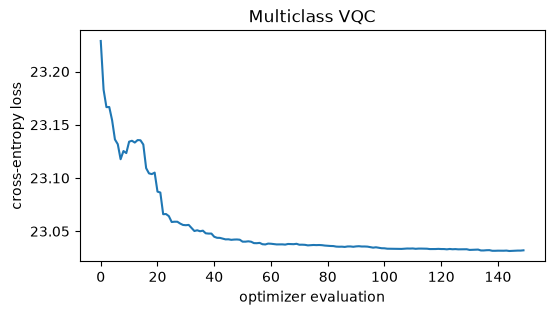

VQC trained in 1036 s


In [21]:
if RUN_MULTICLASS:
    mc = pd.concat([g.sample(min(len(g), MC_PER_CLASS), random_state=SEED) for _, g in attacks.groupby("Family")])
    FAMILIES = sorted(mc["Family"].unique())
    Xm_raw = mc[MC_FEATURES].to_numpy(float)
    ym = mc["Family"].map({f: i for i, f in enumerate(FAMILIES)}).to_numpy()
    Xm_tr_raw, Xm_te_raw, ym_tr, ym_te = train_test_split(Xm_raw, ym, test_size=0.4, stratify=ym, random_state=SEED)

    to_q_mc = make_pipeline(StandardScaler(), PCA(N_QUBITS, random_state=SEED), MinMaxScaler((0, np.pi)))
    Xm_tr = to_q_mc.fit_transform(Xm_tr_raw); Xm_te = np.clip(to_q_mc.transform(Xm_te_raw), 0, np.pi)
    print("train", Xm_tr.shape, "test", Xm_te.shape, "| test flows per family:",
          dict(zip(FAMILIES, np.bincount(ym_te))))

    mc_pred = {}
    # VQC (same tuned configuration as the binary task). RawFeatureVector encodes 4 features on 2 qubits, whose
    # 4 outcomes cannot index 7 classes, so in that case the kernel feature map (4 qubits, 16 outcomes) is used instead.
    mc_combo = BEST if BEST.feature_map != "RawFeatureVector" else BEST._replace(feature_map=kernel_fm_name)
    mc_n, mc_maxiter = ((len(Xm_tr), MC_VQC_MAXITER) if mc_combo.optimizer not in GRAD_OPTS
                        else (min(len(Xm_tr), 4 * GRAD_TRAIN), GRAD_MAXITER))        # same gradient-budget rule as in 5b
    print("multiclass VQC configuration:", mc_combo, "| maxiter", mc_maxiter, "| training flows", mc_n)
    cb, _ = make_live_plot("Multiclass VQC")
    algorithm_globals.random_seed = SEED
    vqc_mc = make_vqc(mc_combo.feature_map, mc_combo.ansatz, mc_combo.optimizer, mc_maxiter, callback=cb)
    t0 = time.time(); vqc_mc.fit(Xm_tr[:mc_n], ym_tr[:mc_n]); print(f"VQC trained in {time.time() - t0:.0f} s")
    mc_pred["VQC"] = vqc_mc.predict(Xm_te)

    # QSVM (scikit-learn SVC handles multiclass one-vs-one)
    qsvc_mc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=build_feature_map(kernel_fm_name)), random_state=SEED)
    mc_pred["QSVM"] = qsvc_mc.fit(Xm_tr, ym_tr).predict(Xm_te)

In [22]:
if RUN_MULTICLASS and RUN_QCNN_MULTICLASS:
    scores = np.zeros((len(Xm_te), len(FAMILIES)))
    for k, fam in enumerate(FAMILIES):
        t0 = time.time()
        m = make_qcnn(MC_QCNN_MAXITER)
        m.fit(Xm_tr, np.where(ym_tr == k, 1, -1))
        scores[:, k] = np.ravel(m.neural_network.forward(Xm_te, m.weights))   # <Z> score, higher = this family
        print(f"QCNN one-vs-rest: {fam} done ({time.time() - t0:.0f} s)", flush=True)
    mc_pred["QCNN"] = scores.argmax(1)

QCNN one-vs-rest: BoT done (165 s)


QCNN one-vs-rest: BruteForce done (142 s)


QCNN one-vs-rest: DDoS done (124 s)


QCNN one-vs-rest: DoS done (178 s)


QCNN one-vs-rest: Infiltration done (139 s)


QCNN one-vs-rest: PortScan done (107 s)


QCNN one-vs-rest: WebAttack done (115 s)


Per-family F1 (%), this notebook, 4 PCA angles for every model


,VQC,QSVM,QCNN,RF,SVM,CNN
BoT,44.09,87.72,54.32,90.00,22.95,47.89
BruteForce,38.89,93.33,37.74,93.75,27.59,36.36
DDoS,0.00,81.97,74.29,88.52,65.57,71.23
DoS,0.00,73.81,37.21,81.69,70.97,72.13
Infiltration,0.00,56.25,8.00,75.00,74.07,82.76
PortScan,0.00,78.57,49.12,79.31,37.74,28.00
WebAttack,0.00,96.88,68.24,91.18,63.04,67.44
macro avg,11.85,81.22,46.99,85.64,51.70,57.97


Per-family F1 (%) reported in the paper (QML-IDS Table VI; the journal's Table 8 differs by a few points per cell)


,VQC,QSVM,QCNN,RF,SVM,CNN
BoT,88.23,97.11,98.45,92.12,94.67,91.45
BruteForce,95.87,99.99,99.99,96.24,93.45,94.42
DDoS,90.54,99.99,96.55,99.34,94.32,96.32
DoS,90.32,90.79,92.45,98.02,99.67,96.15
Infiltration,90.99,99.66,97.42,97.53,99.87,97.15
PortScan,95.45,96.32,97.48,97.45,97.89,96.88
WebAttack,92.78,96.67,97.83,96.89,98.21,96.55
macro avg,92.03,97.22,97.17,96.80,96.87,95.56


Verdicts on the macro-averaged F1 (within 3 points or above = reproduced):
  VQC   paper macro F1  92.03 | notebook  11.85 -> not reached here
  QSVM  paper macro F1  97.22 | notebook  81.22 -> not reached here
  QCNN  paper macro F1  97.17 | notebook  46.99 -> not reached here
  RF    paper macro F1  96.80 | notebook  85.64 -> not reached here
  SVM   paper macro F1  96.87 | notebook  51.70 -> not reached here
  CNN   paper macro F1  95.56 | notebook  57.97 -> not reached here


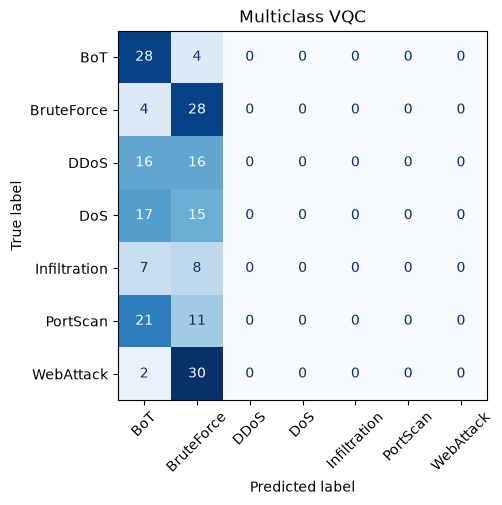

In [23]:
if RUN_MULTICLASS:
    mc_pred.update(run_classical(Xm_tr, ym_tr, Xm_te, n_classes=len(FAMILIES)))

    PAPER_MC_CICIDS17 = pd.DataFrame({   # QML-IDS (arXiv:2410.16308), Table VI, F1 in %
        "VQC":  [88.23, 95.87, 90.54, 90.32, 90.99, 95.45, 92.78],
        "QSVM": [97.11, 99.99, 99.99, 90.79, 99.66, 96.32, 96.67],
        "QCNN": [98.45, 99.99, 96.55, 92.45, 97.42, 97.48, 97.83],
        "RF":   [92.12, 96.24, 99.34, 98.02, 97.53, 97.45, 96.89],
        "SVM":  [94.67, 93.45, 94.32, 99.67, 99.87, 97.89, 98.21],
        "CNN":  [91.45, 94.42, 96.32, 96.15, 97.15, 96.88, 96.55],
    }, index=["BoT", "BruteForce", "DDoS", "DoS", "Infiltration", "PortScan", "WebAttack"])

    ours = pd.DataFrame({m: 100 * f1_score(ym_te, p, average=None, labels=range(len(FAMILIES)), zero_division=0)
                         for m, p in mc_pred.items()}, index=FAMILIES).round(2)
    ours.loc["macro avg"] = ours.mean().round(2)
    PAPER_MC_CICIDS17.loc["macro avg"] = PAPER_MC_CICIDS17.mean().round(2)
    print("Per-family F1 (%), this notebook, 4 PCA angles for every model")
    display(ours)
    print("Per-family F1 (%) reported in the paper (QML-IDS Table VI; the journal's Table 8 differs by a few points per cell)")
    display(PAPER_MC_CICIDS17)
    print("Verdicts on the macro-averaged F1 (within 3 points or above = reproduced):")
    for m in ours.columns:
        if m in PAPER_MC_CICIDS17.columns:
            o, p = ours.loc["macro avg", m], PAPER_MC_CICIDS17.loc["macro avg", m]
            print(f"  {m:5s} paper macro F1 {p:6.2f} | notebook {o:6.2f} -> {'reproduced' if o >= p - 3 else 'not reached here'}")
    if "QCNN" not in ours.columns:
        print("  QCNN  one-vs-rest multiclass QCNN skipped (RUN_QCNN_MULTICLASS = False in FAST_MODE) -> cannot be checked in this run")

    ConfusionMatrixDisplay(confusion_matrix(ym_te, mc_pred["VQC"]), display_labels=FAMILIES).plot(
        cmap="Blues", xticks_rotation=45, colorbar=False)
    plt.title("Multiclass VQC"); plt.show()

## Reading the paper critically

Some points to raise with students, whatever numbers your run produces:

- **The quantum models see 4 numbers per flow.** PCA compresses dozens of flow statistics into as many angles as there are qubits. Compare the classical baselines on the same 4 angles with the same baselines on all features: the gap measures what the qubit budget costs, independent of whether the model is quantum.
- **Simulation is not speed-up.** Every quantum result here was computed by a classical simulator. A 4-qubit circuit is easy to simulate, so these experiments cannot show a quantum advantage; they show that the hybrid pipeline works end to end.
- **Training cost differs sharply between optimisers.** COBYLA and SPSA need one or two circuit evaluations per step. ADAM and GradientDescent need parameter-shift gradients, which on a 16-parameter ansatz is 32 extra circuits per sample per step. The hyperparameter table records the wall-clock times.
- **Noise.** The fake-device table shows how much F1 survives the move from the ideal simulator to calibrated device noise, and how much the transpiler level, dynamical decoupling and readout correction recover.
- **Sample size.** The paper does not say how many flows it trained on. This notebook uses a few hundred per task, so expect run-to-run variation of a few points, especially for the small classes in the multiclass task.

**Where the paper is thin.** The paper does not report qubit counts, feature reduction, sample sizes, train/test split, shots or iteration budgets, and gives no code; a reader cannot tell how much of the 94-97 % F1 comes from the quantum model and how much from the data preparation. Its classical baselines are trained with default settings and, apparently, on a different input representation than the quantum models, so "quantum outperforms classical" (Section 6.3) is not a like-for-like comparison. The noisy-device scores (Tables II-III, Table 5) differ from the simulator by only 1-3 points, which is hard to square with 100+-gate ZZFeatureMap circuits on 2024 hardware unless the circuits were very shallow or heavily error-mitigated; the notebook's stored-noise table shows how large the gap can be. The hyper-parameter search (Table I) lists options but reports no scores, so this notebook's Section 5b is the only place where that comparison is visible.

## Exercises

1. Set `RUN_FULL_GRID = True` and run Section 5b overnight. Does the coordinate-wise search find the same winner as the full grid?
2. Change `N_QUBITS` to 8 (the QCNN needs a power of two) and compare the 8-angle classical baselines with the quantum models. What does the extra PCA variance buy?
3. Replace the PCA by `SelectKBest(f_classif, k=N_QUBITS)` so that each qubit carries one named flow feature. Which four features does it pick, and does the VQC change?
4. In Section 6, switch the dynamical-decoupling sequence to `[XGate(), YGate(), XGate(), YGate()]` (XY4) and compare with X-X.
5. Repeat the binary task with 5 different `SEED` values and report mean +- std for each model. Which of the paper's gaps between models survive the noise of sampling?

In [24]:
elapsed = (time.time() - NOTEBOOK_T0) / 60
print(f"FAST_MODE = {FAST_MODE}, RUN_FULL_GRID = {RUN_FULL_GRID}, RUN_MULTICLASS = {RUN_MULTICLASS}, RUN_QCNN_MULTICLASS = {RUN_QCNN_MULTICLASS}")
print(f"whole notebook: {elapsed:.1f} min wall clock | BEST = {BEST} | kernel map = {kernel_fm_name}")

FAST_MODE = False, RUN_FULL_GRID = False, RUN_MULTICLASS = True, RUN_QCNN_MULTICLASS = True
whole notebook: 89.0 min wall clock | BEST = Combo(feature_map='ZZFeatureMap', ansatz='TwoLocal', optimizer='SPSA') | kernel map = ZZFeatureMap
